In [1]:
import torch
import numpy as np 
import matplotlib.pyplot as plt
import math

DATA GENERATION -> 3 clusters with 2D normal distribution

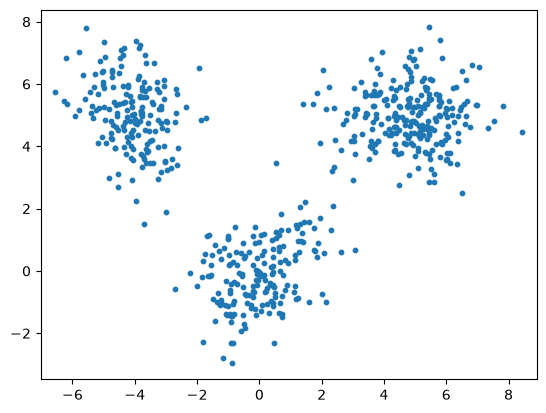

In [2]:
rng = np.random.default_rng(42)

# True GNN parameter
true_means = np.array([
    [0 , 0],
    [5 , 5],
    [-4, 5]
])

true_cov = np.array([
    [[1, 0.3] , [0.3, 1]],
    [[1.5, 0], [0, 0.8]],
    [[0.8, -0.2], [-0.2, 1.2]]
])

true_weights = np.array([0.3, 0.4, 0.3])

n = 600
K = 3

# Tirage des variable lattente 
Z = rng.choice(K, size=n, p=true_weights)

# Data generation 
X = np.array([
    rng.multivariate_normal(true_means[k], true_cov[k])
    for k in Z
    ])

plt.scatter(X[:,0], X[:,1], s=10)
plt.axis('equal')
plt.show()

In [3]:
# Initialisation du tenseur pour les data du GMM X
x_torch = torch.tensor(X,dtype=torch.float64,requires_grad=True)
n, d = x_torch.shape
K = 3

print(x_torch.shape)
print(x_torch.requires_grad)

torch.Size([600, 2])
True


Fonction de l'algo EM 

In [4]:
def initialization_torch(x, K, rng):
    """Initialize the parameters of the GMM"""
    n, d = x.shape

    # Initialize weights
    weight = torch.ones(K, dtype=x.dtype, device=x.device) / K

    # Randomly select K observations as initial means
    indices = rng.choice(n, K, replace=False)
    mean = x[indices].detach().clone()

    # Initialize covariance matrices
    cov = torch.eye(d, dtype=x.dtype, device=x.device).repeat(K, 1, 1)

    return weight, mean, cov

def gaussian_log_density_torch(x, mean, cov):
    n, d = x.shape

    diff = x - mean

    # Solve Sigma @ z = diff.T
    solved = torch.linalg.solve(cov, diff.T).T

    quadratic = torch.sum(diff * solved, dim=1)

    sign, logdet = torch.linalg.slogdet(cov)

    return -0.5 * (
        d * math.log(2 * math.pi)
        + logdet
        + quadratic
    )

## Le fait de passer au log evite les probleme lie au tres petite proba
def e_step_torch(x, weights, mean, cov) : 
    """E-step, compute responsibilities."""
    K = len(weights)
    
    log_gamma = torch.stack([
        torch.log(weights[k]) + gaussian_log_density_torch(x,mean[k],cov[k])
        for k in range(K)
    ], dim=1)
    
    log_normalization = torch.logsumexp(log_gamma, dim=1, keepdim=True)
    gamma = torch.exp(log_gamma - log_normalization)
    
    return gamma 

def m_step_torch(x, responsibilities ) : 
    """M-step, update of the parameters"""
    n, d = x.shape  #(n, d) 
    K = responsibilities.shape[1] # responsibilities (n,K)
    
    normalization = torch.sum(responsibilities, dim= 0)   #(K,)

    # update weights
    new_weight = normalization / n  #(K,)
    
    # update mean
    new_mean = (responsibilities.T @ x) / normalization[:,None]     #(K,d)
    
    # update covariance
    list_cov = []
    for k in range(K) : 
        diff = (x - new_mean[k])    #(n,d)
        weighted_diff = responsibilities[:, k, None] * diff   #(n,d)
        cov_k = (diff.T @ weighted_diff ) / normalization[k] #(d,d)
        list_cov.append(cov_k)
        
    new_cov = torch.stack(list_cov, dim=0)
    eps = 1e-6
    new_cov = new_cov + eps * torch.eye(d, dtype = x.dtype, device= x.device).unsqueeze(0)
        
    
    return [new_weight, new_mean, new_cov]

def log_likelihood_torch(x,weight,mean,cov) : 
    """Compute the log-likelihood"""
    K = len(weight)
    
    log_p = torch.stack([
        torch.log(weight[k]) + gaussian_log_density_torch(x,mean[k],cov[k])
        for k in range(K)
    ], dim=1)
    

    return torch.logsumexp(log_p, dim=1).sum()

def em_algorithm_torch(x, weight, mean, cov, n_iter = 100) : 
    """Run of the Expectation-Maximization Algo"""
    history = []
    
    for i in range(n_iter) : 
        # E-step
        responsibilities = e_step_torch(x,weights= weight, mean= mean, cov= cov)
        #M-step
        weight, mean, cov = m_step_torch(x,responsibilities= responsibilities)
        #compute log-likelihood
        Ll = log_likelihood_torch(x,weight=weight,mean=mean,cov=cov)
        history.append(Ll.item())
    
    return weight, mean, cov, history

Estimated weights: [0.30334908 0.29168694 0.40496398]
True weights: [0.3 0.4 0.3]
Estimated means: [[-0.00868232 -0.10009177]
 [-4.0794168   5.03605073]
 [ 4.80864809  4.95411073]]
True means: [[ 0  0]
 [ 5  5]
 [-4  5]]
Estimated covariances: [[[ 1.13317086  0.39775747]
  [ 0.39775747  1.10579732]]

 [[ 0.76300413 -0.27614611]
  [-0.27614611  1.29931316]]

 [[ 1.43553648  0.00218501]
  [ 0.00218501  0.86914987]]]
True covariances: [[[ 1.   0.3]
  [ 0.3  1. ]]

 [[ 1.5  0. ]
  [ 0.   0.8]]

 [[ 0.8 -0.2]
  [-0.2  1.2]]]


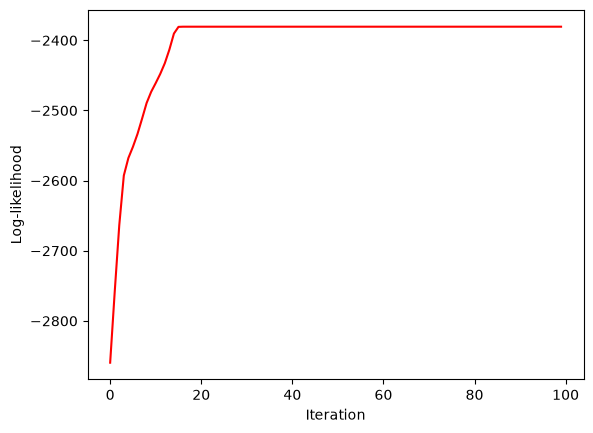

In [5]:
rng = np.random.default_rng(42)
n_iter = 100

# Initialization directly in PyTorch
weight, mean, cov = initialization_torch(x_torch, K, rng)

# Run differentiable EM
em_weight, em_mean, em_cov, em_history = em_algorithm_torch(
    x=x_torch,
    weight=weight,
    mean=mean,
    cov=cov,
    n_iter=n_iter
)

# Results
print("Estimated weights:", em_weight.detach().numpy())
print("True weights:", true_weights)

print("Estimated means:", em_mean.detach().numpy())
print("True means:", true_means)

print("Estimated covariances:", em_cov.detach().numpy())
print("True covariances:", true_cov)

# Plot log-likelihood
plt.plot(em_history, color="red")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()

In [6]:
# Test de différentiabilité
loss = em_mean.square().sum()

gradient = torch.autograd.grad(loss, x_torch)[0]

print("Gradient shape:", gradient.shape)
print("Gradient norm:", gradient.norm().item())
print("All finite:", torch.isfinite(gradient).all().item())

Gradient shape: torch.Size([600, 2])
Gradient norm: 1.3565045418507147
All finite: True


In [7]:
# Direction aléatoire de norme 1 dans l'espace des données
generator = torch.Generator(device=x_torch.device).manual_seed(42)
direction = torch.randn(
    x_torch.shape,
    dtype=x_torch.dtype,
    device=x_torch.device,
    generator=generator,
)
direction = direction / direction.norm()

# Dérivée directionnelle prédite par autograd
autograd_value = (gradient * direction).sum()

@torch.no_grad()
def loss_at(x):
    _, fitted_means, _, _ = em_algorithm_torch(
        x=x, weight=weight, mean=mean, cov=cov, n_iter=n_iter
    )
    return fitted_means.square().sum()

for h in (1e-3, 1e-4, 1e-5):
    finite_diff = (
        loss_at(x_torch + h * direction)
        - loss_at(x_torch - h * direction)
    ) / (2 * h)

    error = (autograd_value - finite_diff).abs().item()
    print(f"h={h:.0e} | autograd={autograd_value.item():.10f} "
          f"| finite diff={finite_diff.item():.10f} | error={error:.2e}")

h=1e-03 | autograd=-0.0477173987 | finite diff=-0.0477173987 | error=1.63e-11
h=1e-04 | autograd=-0.0477173987 | finite diff=-0.0477173987 | error=3.05e-11
h=1e-05 | autograd=-0.0477173987 | finite diff=-0.0477173941 | error=4.58e-09


Implementation Optimal transport function

In [ ]:
def sqrt_sigma(sigma) : 
    """Compute the square of the matrix using spectral decomposition"""
    eigh, Q = torch.linalg.eigh(sigma)
    sqrt_eigh = torch.sqrt(eigh)
    eigh_matrix = torch.diag(sqrt_eigh)
    spectral_decomposition = Q @ eigh_matrix @ Q.T
    return spectral_decomposition

def wasserstein2_dist(gaussian_1, gaussian_2) : 
    """Compute the wasserstein distance between two gaussian mesures"""
    diff_mean = (gaussian_1[0] - gaussian_2[0])
    norm_diff_mean = diff_mean @ diff_mean.T
    
    sqrt_cov_1 = sqrt_sigma(gaussian_1[1])
    eigh_right = torch.linalg.eigvalsh(sqrt_cov_1 @ gaussian_2[1] @ sqrt_cov_1)
    bures_dist_2 = torch.sum(torch.sqrt(eigh_right))

    trace = torch.trace(gaussian_1[1] + gaussian_2[1]) - (2 * bures_dist_2)
    
    return norm_diff_mean + trace

def cost_matrix(GMM_1, GMM_2) : 
    """"Computation of the cost matrix for the kantorovich problem"""
    cost_matrix = []
    for i in range(len(GMM_1[0])) : 
        l = []
        for j in range(len(GMM_2[0])) : 
            l.append(wasserstein2_dist((GMM_1[1][i],GMM_1[2][i]), (GMM_2[1][j],GMM_2[2][j])))
        l = torch.stack(l,dim=0)
        cost_matrix.append(l)
    cost_matrix = torch.stack(cost_matrix, dim=0)
    return cost_matrix
    

def MW2(GMM_1, GMM_2) : 
    """Computation of the distance between two GMM model"""
    cost_mat = cost_matrix(GMM_1,GMM_2)
    

In [17]:
dtype = torch.float64
mean = torch.zeros(2, dtype=dtype)

# 1. Vérifier la valeur de W₂²
identity = torch.eye(2, dtype=dtype)
cost = wasserstein2_dist((mean, identity), (mean, 4 * identity))

torch.testing.assert_close(cost, torch.tensor(2.0, dtype=dtype))
print(f"Test de valeur OK — W₂² = {cost.item():.8f}")

# 2. Vérifier le gradient par rapport à la première covariance
cov_1 = torch.tensor(
    [[2.0, 0.3], [0.3, 1.0]], dtype=dtype, requires_grad=True
)
cov_2 = torch.tensor([[1.0, -0.2], [-0.2, 3.0]], dtype=dtype)

direction = torch.tensor([[0.4, 0.2], [0.2, -0.3]], dtype=dtype)
direction = direction / direction.norm()

cost = wasserstein2_dist((mean, cov_1), (mean, cov_2))
(gradient,) = torch.autograd.grad(cost, cov_1)
autograd_value = (gradient * direction).sum()

h = 1e-5
with torch.no_grad():
    cost_plus = wasserstein2_dist((mean, cov_1 + h * direction), (mean, cov_2))
    cost_minus = wasserstein2_dist((mean, cov_1 - h * direction), (mean, cov_2))
    finite_diff = (cost_plus - cost_minus) / (2 * h)

print(f"Autograd         = {autograd_value.item():.10f}")
print(f"Différence finie = {finite_diff.item():.10f}")
print(f"Erreur absolue   = {(autograd_value - finite_diff).abs().item():.2e}")

torch.testing.assert_close(autograd_value, finite_diff, rtol=1e-6, atol=1e-8)
print("Test du gradient OK")

# Test de la fonction cost matrix
dtype = torch.float64

weights = torch.tensor([0.3, 0.4, 0.3], dtype=dtype)
means = torch.tensor(
    [[0.0, 0.0], [3.0, 0.0], [0.0, 4.0]],
    dtype=dtype,
    requires_grad=True,
)
covariances = torch.eye(2, dtype=dtype).repeat(3, 1, 1)

gmm = (weights, means, covariances)
costs = cost_matrix(gmm, gmm)

expected = torch.tensor(
    [[0.0, 9.0, 16.0],
     [9.0, 0.0, 25.0],
     [16.0, 25.0, 0.0]],
    dtype=dtype,
)

torch.testing.assert_close(costs, expected)
print("Matrice de coûts OK")

(gradient,) = torch.autograd.grad(costs[0, 1], means)
expected_gradient = torch.tensor(
    [[-6.0, 0.0], [6.0, 0.0], [0.0, 0.0]],
    dtype=dtype,
)

torch.testing.assert_close(gradient, expected_gradient)
print("Gradient par rapport aux moyennes OK")

Test de valeur OK — W₂² = 2.00000000
Autograd         = 0.7227421883
Différence finie = 0.7227421882
Erreur absolue   = 8.03e-11
Test du gradient OK
Matrice de coûts OK
Gradient par rapport aux moyennes OK
